<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import gdown, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, numpy as np
gdown.download(id='1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs', output='clean.parquet', quiet=False)
df = pd.read_parquet('clean.parquet')

Downloading...
From (original): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs
From (redirected): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs&confirm=t&uuid=bd75b2fe-7e23-4b52-b0e9-ffa4fbf30875
To: /content/clean.parquet
100%|██████████| 139M/139M [00:01<00:00, 89.3MB/s]


## 1. Target Distribution — **Turki**

In [3]:
df["is_fraud"].value_counts()

,count
is_fraud,
0,1842743
1,9651


Number of legitimate transactions are 1,842,743 , and the fraud ones are 9651.

In [4]:
df["is_fraud"].value_counts(normalize=True) * 100

,proportion
is_fraud,
0,99.478999
1,0.521001


99.48% of the transactions are legitimate, and the fraud transcations are 0.52%

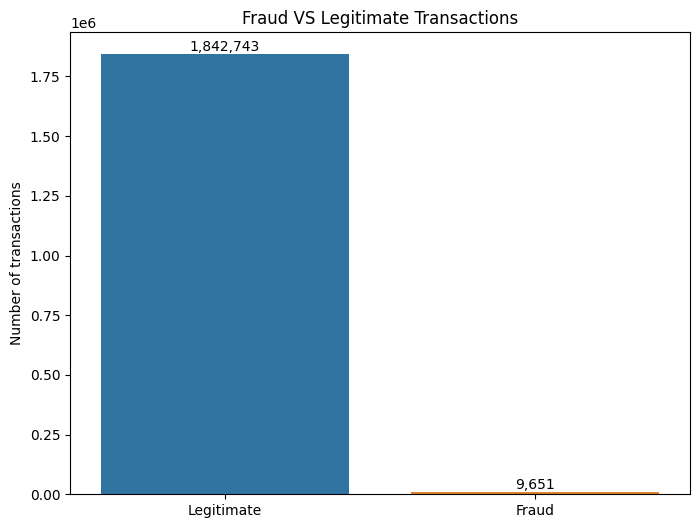

In [5]:
plt.figure(figsize=(8,6))
fig = sns.countplot(df, x="is_fraud",hue="is_fraud", legend=False);
plt.title("Fraud VS Legitimate Transactions")
fig.set_xticks([0, 1])
fig.set_xticklabels(["Legitimate", "Fraud"])
plt.ylabel("Number of transactions")
for c in fig.containers:
    fig.bar_label(c, fmt='{:,.0f}')
plt.xlabel("");

**Observation:** The dataset is highly imbalanced. Legitimate transactions are far more common than fraud, so the fraud bar is barely visible.

**Fraud is 0.52% of all transactions** (9,651 out of 1,852,394), while legitimate transactions are 99.48%. The fraud bar is barely visible because the data is highly imbalanced.

**Effect on accuracy:** Accuracy is not a reliable metric here. A model that always predicts "legitimate" would score about 99.5% accuracy while catching no fraud at all.

## 2. Amount Distribution — Abdulmohsen

In [18]:
#Summary statistics for transaction amounts
df['amt'].describe().apply('{:,.2f}'.format)

,amt
count,"1,852,394.00"
mean,70.06
std,159.25
min,1.00
25%,9.64
50%,47.45
75%,83.10
max,"28,948.90"


**Summary:** Transaction amounts range from \$1.00 to \$28,948.90. The middle 50% fall between \$9.64 and \$83.10, with a median of \$47.45 and a mean of \$70.06.

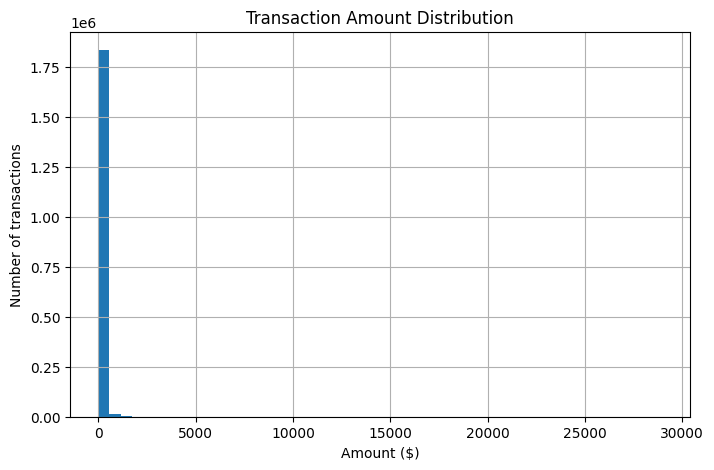

In [7]:
#Plot the distribution of transaction amounts
plt.figure(figsize=(8, 5))
df['amt'].hist(bins=50)
plt.title('Transaction Amount Distribution')
plt.xlabel('Amount ($)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** Transaction amounts are strongly right-skewed: 75% are at or below \$83.10, while the maximum reaches \$28,948.90. The mean (\$70.06) is higher than the median (\$47.45), reflecting the influence of large amounts.

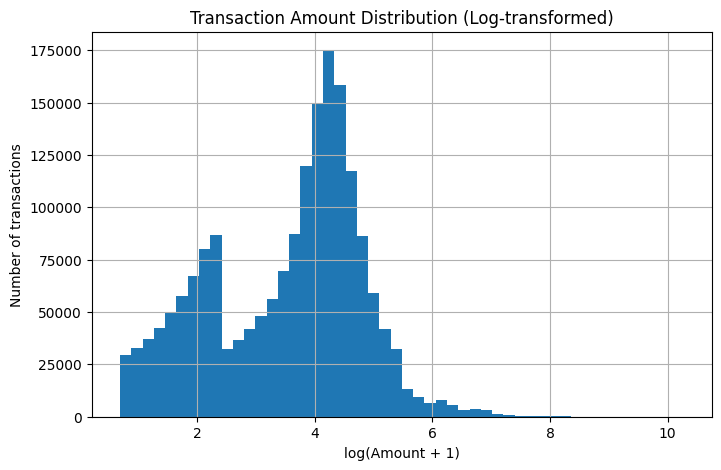

In [8]:
#Plot amounts after a log transformation
plt.figure(figsize=(8, 5))
np.log1p(df['amt']).hist(bins=50)
plt.title('Transaction Amount Distribution (Log-transformed)')
plt.xlabel('log(Amount + 1)')
plt.ylabel('Number of transactions')
plt.show()

**Observation:** The log transformation makes the distribution clearer, revealing a main peak around log(Amount + 1) = 4.2 and a smaller peak near 2.3. Large amounts remain in the right tail, but no longer compress the smaller amounts into a single dominant bar.

**Unexpected:** The log-transformed histogram reveals two distinct peaks that were not visible on the original scale; the reason for this pattern needs further investigation.

The main peak (4.2) corresponds to about \$65, and the smaller peak (2.3) to about \$9.


## 3. Hour and Age Distribution — Rayan

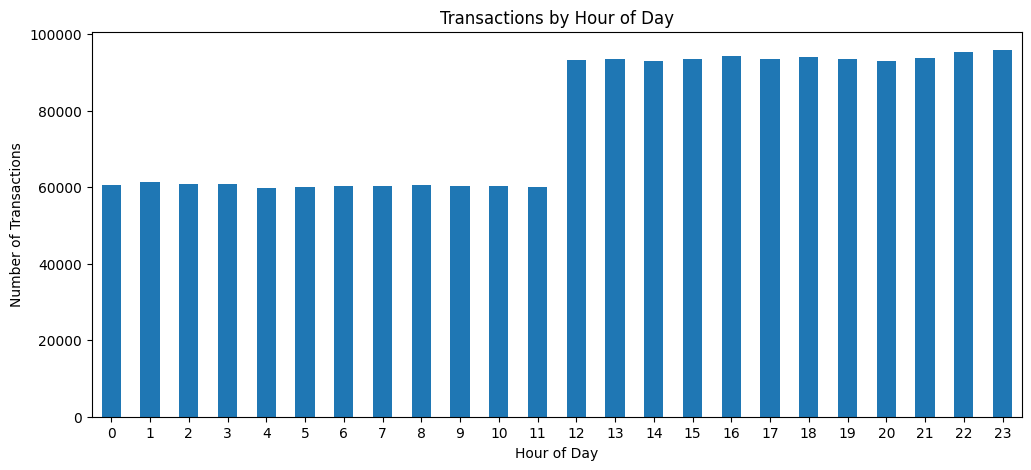

Busiest hour: 23
Transactions: 95902
Quietest hour: 4
Transactions: 59938


In [9]:

# Extract the transaction hour (0-23)
hour = df['trans_date_trans_time'].dt.hour

# Count transactions for each hour
hour_counts = hour.value_counts().reindex(
    range(24), fill_value=0
)

# Display the chart
plt.figure(figsize=(12, 5))
hour_counts.plot(kind='bar')

plt.title('Transactions by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()

# Find the busiest and quietest hours
print("Busiest hour:", hour_counts.idxmax())
print("Transactions:", hour_counts.max())

print("Quietest hour:", hour_counts.idxmin())
print("Transactions:", hour_counts.min())


**Note:** The highest number of transactions occurred at 23:00 (95,902 transactions), while the lowest was at 04:00 (59,938 transactions). Transaction counts were generally higher from 12:00 to 23:00.

**Unexpected:** There is a noticeable increase in transaction counts starting at 12:00. The reason for this sudden change is unclear and may need further investigation.

count    1.852394e+06
mean     4.626388e+01
std      1.740998e+01
min      1.392197e+01
25%      3.288706e+01
50%      4.424367e+01
75%      5.731143e+01
max      9.616975e+01
dtype: float64


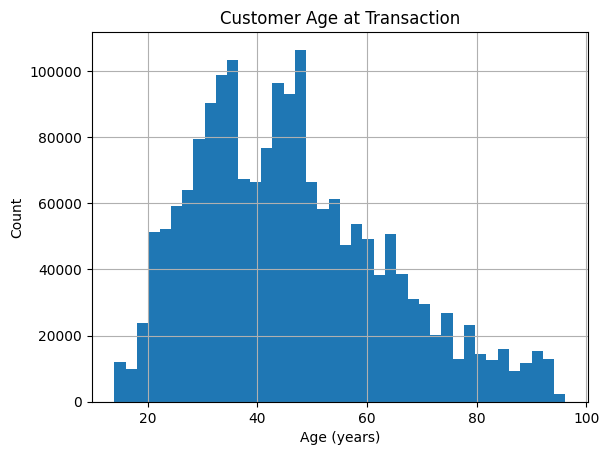

In [10]:

# Calculate customer age at transaction
age = (df['trans_date_trans_time'] - df['dob']).dt.days / 365.25

# Age statistics
print(age.describe())


# Age distribution
age.hist(bins=40)
plt.title('Customer Age at Transaction')
plt.xlabel('Age (years)')
plt.ylabel('Count')
plt.show()


**Note:** The average customer age is 46.26 years, with 50% of transactions involving customers aged approximately 33–57. Ages range from about 14 to 96 years, with no clearly impossible ages observed.

## 4. What Relates to Fraud — Lana

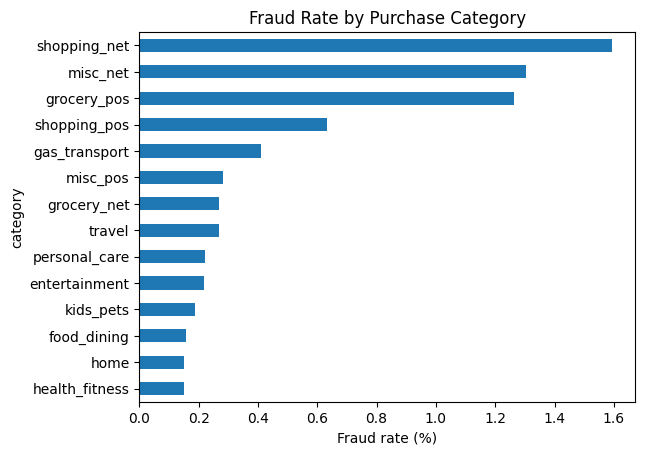

In [11]:
# Fraud rate for each category
rate = df.groupby('category')['is_fraud'].mean().sort_values() * 100
rate.plot(kind='barh')
plt.title('Fraud Rate by Purchase Category')
plt.xlabel('Fraud rate (%)')
plt.show()

**Observation:** As we can see from the chart above, some spending categories carry far more risk than the rest.

- **Highest risk:** `shopping_net` (about 1.6%), `misc_net` (about 1.3%), and `grocery_pos` (about 1.25%). These rates are roughly **2.5–3 times** the overall fraud rate of 0.52%.
- **Lowest risk:** `health_fitness`, `home`, and `food_dining` (about 0.15% each). The riskiest category has about **10 times** the fraud rate of the safest ones.
- **Online purchases stand out:** two of the top three categories end in `_net`, meaning online purchases. Online payments don't need the physical card, so stolen card details are easier to use.
- **Everyday spending is safer:** categories like home, food, health, and kids/pets are routine purchases that fraudsters rarely target.

**Takeaway:** Purchase category is clearly related to fraud and would be a useful feature when building the model.

is_fraud
0     47.24
1    390.00
Name: amt, dtype: float64
Difference: $342.76  |  Ratio: 8.3x


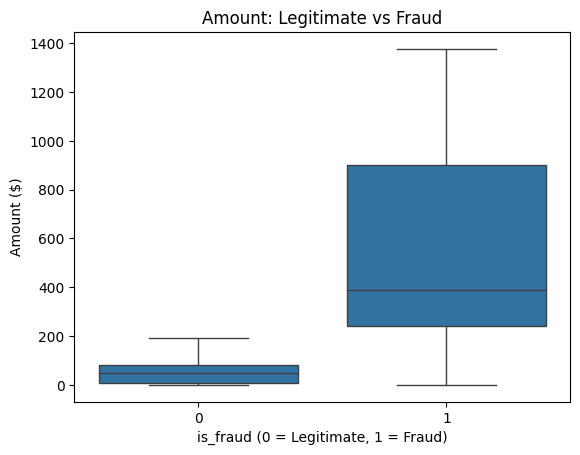

In [12]:
# Median amount for legitimate vs fraud transactions
print(df.groupby('is_fraud')['amt'].median())

m = df.groupby('is_fraud')['amt'].median()
print(f"Difference: ${m[1] - m[0]:.2f}  |  Ratio: {m[1] / m[0]:.1f}x")

# Boxplot comparison (showfliers=False hides extreme outliers to make the boxes readable)
sns.boxplot(data=df, x='is_fraud', y='amt', showfliers=False) #showfliers hides the extreme outliers so the boxes are easier to read.
plt.title('Amount: Legitimate vs Fraud')
plt.xlabel('is_fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Amount ($)')
plt.show()


**Observation:** This chart compares transaction amounts for legitimate and fraudulent transactions.

Fraudulent transactions involve much larger amounts. The median fraud amount is **\$390.00**, compared with **\$47.24** for legitimate transactions. That is a difference of about **\$342.76**, or roughly **8.3 times** higher. The fraud box is also much taller, so fraud amounts vary more widely.

This suggests transaction amount is strongly related to fraud and would be a useful feature when building the model.

## 5. Correlation — Joud





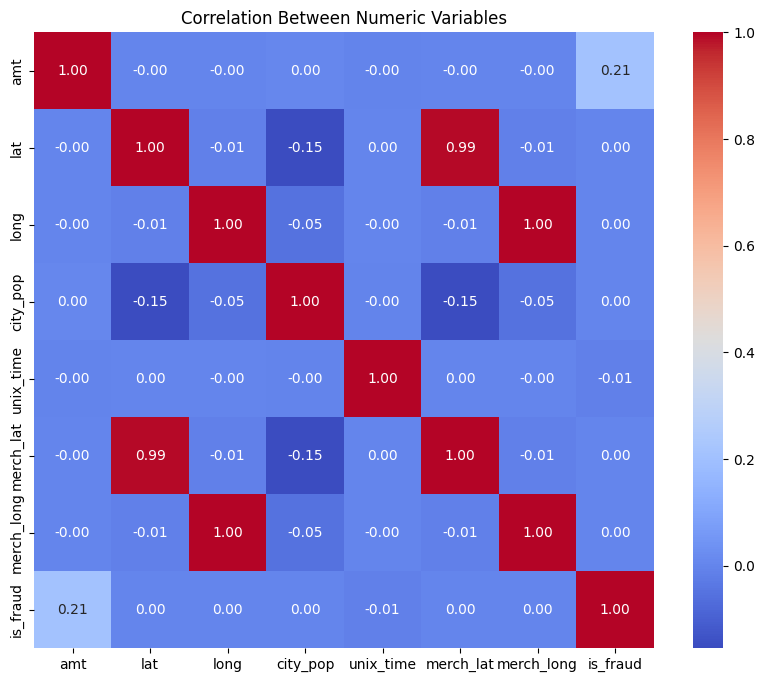

In [17]:
# Correlation heatmap between all numeric columns
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f',
            cmap='coolwarm')
plt.title('Correlation Between Numeric Variables')
plt.show()

**Observation:**
- `lat` / `long`: the customer's location (latitude and longitude).
- `merch_lat` / `merch_long`: the merchant's location where the transaction happened.

The heatmap shows strong correlations between `lat` and `merch_lat` (0.99), and between `long` and `merch_long` (1.00). This means the merchant is almost always located close to the customer.

The strongest correlation with `is_fraud` is `amt` (0.21), which is weak. Other variables show almost no correlation with fraud.

**Takeaway:** Since the customer and merchant coordinates are almost identical, the raw coordinates are redundant. However, the distance between the customer and the merchant could still be a useful feature to test later.

## 6. Fraud Over Time — Faisal

                       transactions  fraud_rate
trans_date_trans_time                          
2019-01                       52525    0.963351
2019-02                       49866    1.036779
2019-03                       70939    0.696373
2019-04                       68078    0.552308
2019-05                       72532    0.562510
2019-06                       86064    0.411322
2019-07                       86596    0.382235
2019-08                       87359    0.437276
2019-09                       70652    0.591632
2019-10                       68758    0.660287
2019-11                       70421    0.550972
2019-12                      141060    0.419680
2020-01                       52202    0.657063
2020-02                       47791    0.703061
2020-03                       72850    0.609472
2020-04                       66892    0.451474
2020-05                       74343    0.708876
2020-06                       87805    0.531860
2020-07                       85848    0

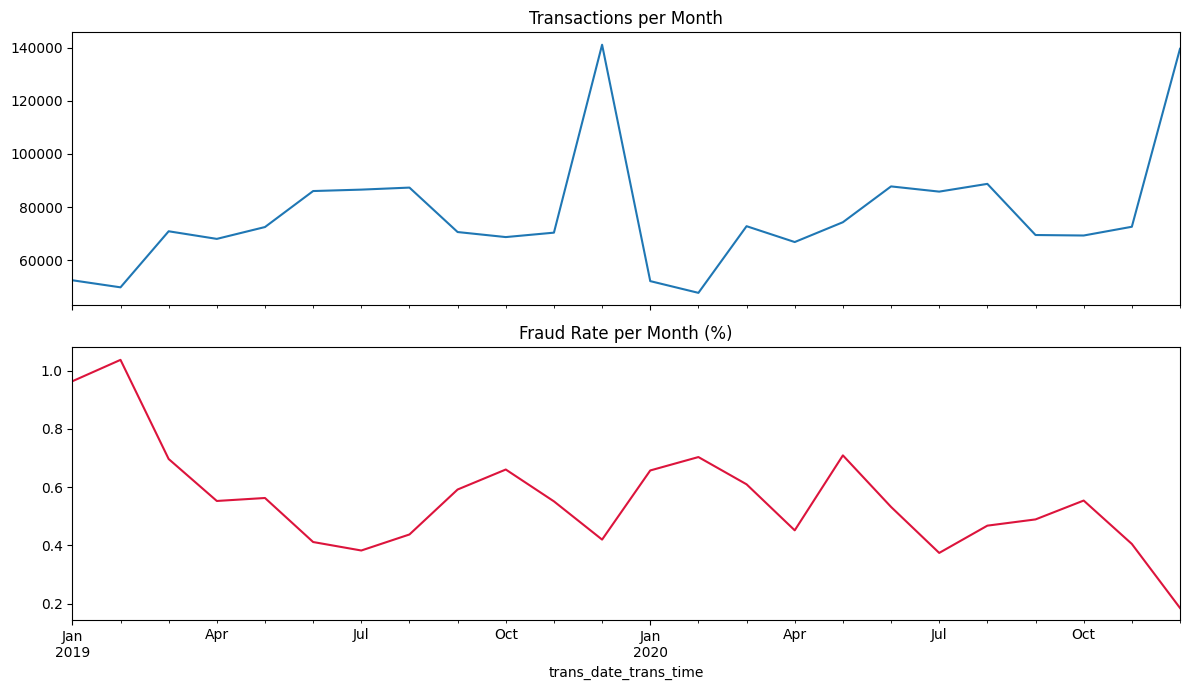

In [15]:

month = df['trans_date_trans_time'].dt.to_period('M')
monthly = df.groupby(month).agg(
    transactions=('is_fraud', 'size'),
    fraud_rate=('is_fraud', 'mean')
)
monthly['fraud_rate'] = monthly['fraud_rate'] * 100
print(monthly)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly['transactions'].plot(ax=axes[0], title='Transactions per Month')
monthly['fraud_rate'].plot(ax=axes[1], title='Fraud Rate per Month (%)', color='crimson')
plt.tight_layout()
plt.show()

**Observation:**
* **Seasonal Patterns:** Transaction volume follows a clear yearly cycle. It peaks in December (around 140,000 transactions, likely due to holiday spending) and is lowest in January–February (around 48,000–52,000). The fraud rate tends to move in the opposite direction: it is high in January–February (0.96%–1.04% in 2019 and 0.66%–0.70% in 2020, with a similar spike in May 2020 at 0.71%) and lowest in July (around 0.37%–0.38%) and December 2020 (0.18%).
* **Fraud Rate Stability:** The fraud rate stays low overall, ranging between 0.18% and 1.04%. It is usually higher in the first months of the year and lower in summer and December.
* **Comparison Between 2019 and 2020:** Transaction volume was very consistent across both years (e.g., December had 141,060 transactions in 2019 vs 139,538 in 2020). The overall fraud rate, however, was lower in 2020 (0.48%) than in 2019 (0.56%). The biggest drops were in January–February (from about 1.0% to 0.7%) and December (from 0.42% to 0.18%). A few months, such as May and June, were higher in 2020.

## 7. The Unexpected — Dhai

This section collects the findings that surprised us during the analysis, and what they mean for the next stages of the project.


In [23]:
#Number of transactions, fraud cases, and fraud rate per year
year = df['trans_date_trans_time'].dt.year.rename('year')
yearly = df.groupby(year)['is_fraud'].agg(transactions='size', fraud_cases='sum', fraud_rate='mean')
yearly['fraud_rate'] = yearly['fraud_rate'] * 100
print(yearly.round(2))

#Fraud cases in December of each year
dec = df[df['trans_date_trans_time'].dt.month == 12]
print(dec.groupby(dec['trans_date_trans_time'].dt.year.rename('year'))['is_fraud'].sum())


      transactions  fraud_cases  fraud_rate
year                                       
2019        924850         5220        0.56
2020        927544         4431        0.48
year
2019    592
2020    258
Name: is_fraud, dtype: int64


**1. The fraud rate changed between the two years.**
Transaction volume was almost identical (924,850 in 2019 vs 927,544 in 2020), but the fraud rate dropped from 0.56% to 0.48%. The biggest gap was in December: 592 fraud cases in 2019 vs only 258 in 2020. This shows the data changes over time, which is exactly what our project aims to monitor.

**2. Transactions jump suddenly at 12:00.** *(Section 3)*
The number of transactions stays flat at around 60,000 per hour until 11:00, then jumps to around 93,000 at 12:00 and stays flat again. Real customer behavior would change gradually, so this is likely a result of the data being simulated.

**3. Transaction amounts have two peaks.** *(Section 2)*
The log-scale histogram shows two groups of purchases: small ones around \$9 and regular ones around \$65. This was not visible on the original scale.

**4. A strong difference with a weak correlation.** *(Sections 4 and 5)*
The median fraud amount is 8.3 times higher than legitimate transactions (\$390 vs \$47.24), yet the correlation between `amt` and `is_fraud` is only 0.21. Correlation measures a straight-line relationship across all transactions, and since fraud is only 0.52% of the data, it underestimates the link. We should not drop features based on correlation alone.

**What this means for the next stages:**
- Since the fraud rate changes over time, we will train the model on 2019 and test it month by month on 2020, instead of a random split.
- Since the data is highly imbalanced, we will evaluate the model with Precision, Recall, and PR-AUC, not Accuracy.
- `amt` and `category` are the most promising features so far.